In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as  mdates
import numpy as np

In [2]:
df = pd.read_csv('data/ECBEuribor3m.csv', parse_dates=True)
df.columns = ['date', 'time period', 'euribor']
df['date'] = pd.to_datetime(df['date'])
df.head()
df.dtypes

date           datetime64[us]
time period               str
euribor               float64
dtype: object

In [3]:
# Set datetime to index, filter out maturities other than 12 months leave out month column.
df.set_index('date', inplace=True)
df = df[['euribor']]
df.head()

,euribor
date,
1994-01-31,6.91
1994-02-28,6.86
1994-03-31,6.75
1994-04-30,6.57
1994-05-31,6.24


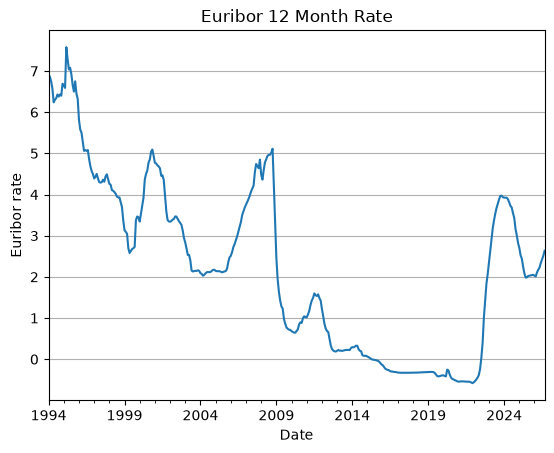

In [4]:
title = 'Euribor 12 Month Rate'
x_label = 'Date'
y_label = 'Euribor rate'
ax = df['euribor'].plot(title=title)
ax.set(xlabel=x_label, ylabel=y_label)
ax.yaxis.grid(True)


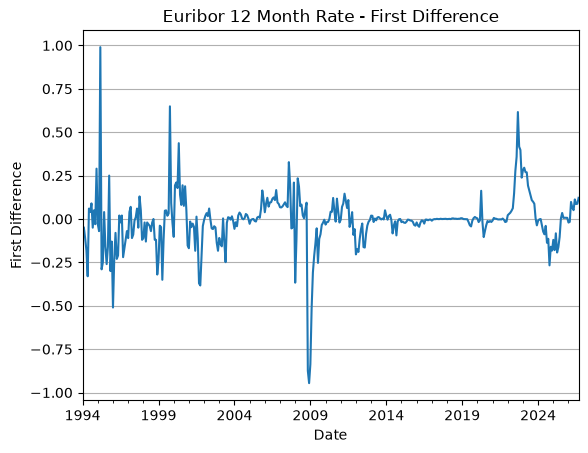

In [25]:
# Euribor not stationary, take first difference to make it stationary.
from statsmodels.tsa.statespace.tools import diff
df['euribor_diff'] = diff(df['euribor'], k_diff=1)
df['euribor_diff'].plot(title='Euribor 12 Month Rate - First Difference', ylabel='First Difference', xlabel='Date').yaxis.grid(True)

Augmented Dickey-Fuller Test: 8.398914388332905e-11


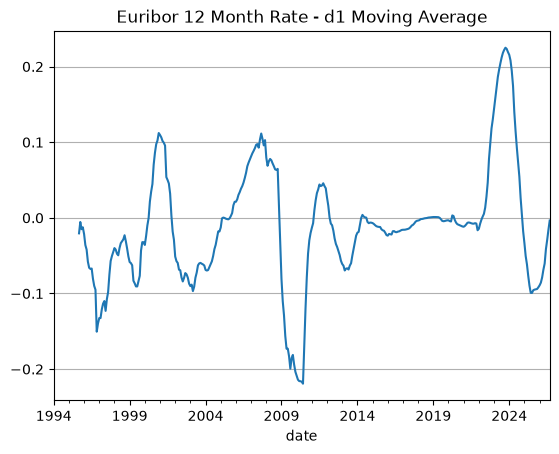

In [26]:
df['euribor_diff_ma'] = df['euribor_diff'].rolling(20).mean()
df['euribor_diff_ma'].plot(title='Euribor 12 Month Rate - d1 Moving Average').yaxis.grid(True)

from statsmodels.tsa.stattools import adfuller
adfuller_result = adfuller(df['euribor_diff'].diff().dropna(), result_object=False)
print(f"Augmented Dickey-Fuller Test: {adfuller_result[1]}")

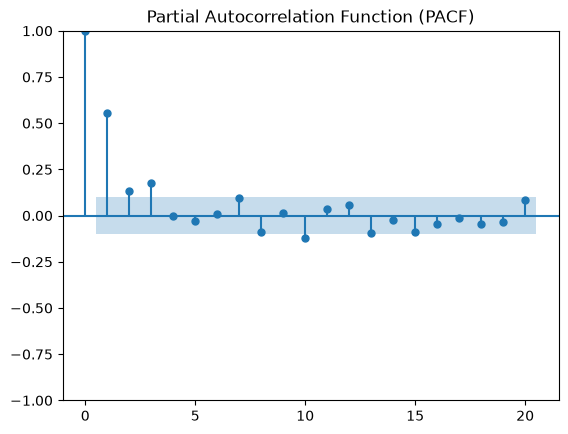

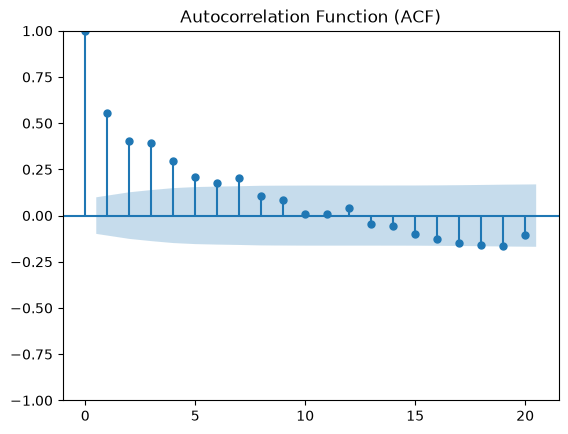

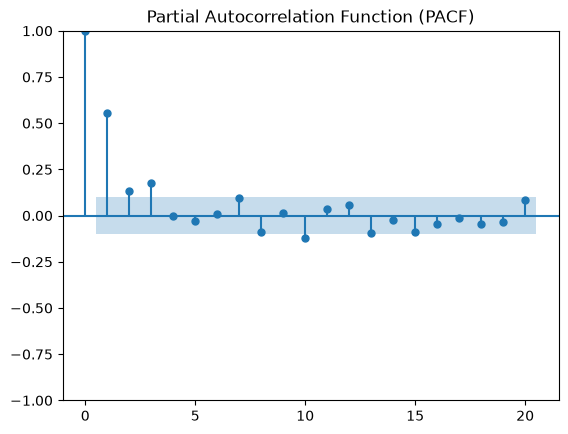

In [8]:
# Augmented Dickey-Fuller Test: <0.05, data is stationary and we can proceed to fit an ARIMA model.
# 12-Month Euribor Rate seems to exhibit volatility clustering

# Figuring out the autoregressive order p and moving average order q values for ARIMA model using ACF and PACF plots.


from statsmodels.tsa.stattools import acovf, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(df['euribor_diff'].dropna().values, lags=20, title='Autocorrelation Function (ACF)')
plot_pacf(df['euribor_diff'].dropna().values, lags=20, title='Partial Autocorrelation Function (PACF)')


Performing stepwise search to minimize aic
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-472.321, Time=0.06 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-328.353, Time=0.04 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-432.214, Time=0.06 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-328.498, Time=0.03 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=-477.574, Time=0.08 sec
 ARIMA(3,1,0)(0,0,0)[0] intercept   : AIC=-488.449, Time=0.07 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=-486.449, Time=0.17 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=-483.150, Time=0.15 sec
 ARIMA(3,1,0)(0,0,0)[0]             : AIC=-490.186, Time=0.05 sec
 ARIMA(2,1,0)(0,0,0)[0]             : AIC=-479.197, Time=0.08 sec
 ARIMA(3,1,1)(0,0,0)[0]             : AIC=-488.186, Time=0.10 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=-484.904, Time=0.10 sec

Best model:  ARIMA(3,1,0)(0,0,0)[0]          
Total fit time: 1.004 seconds
                 coef    std err          z      P>|z|      [0.025      0.975]
---------

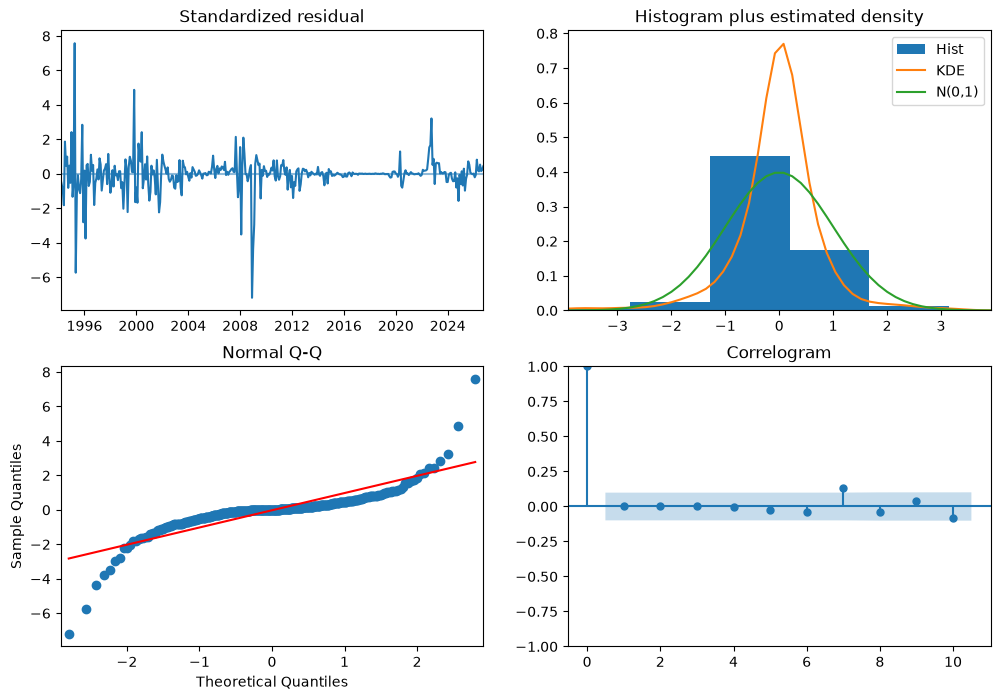

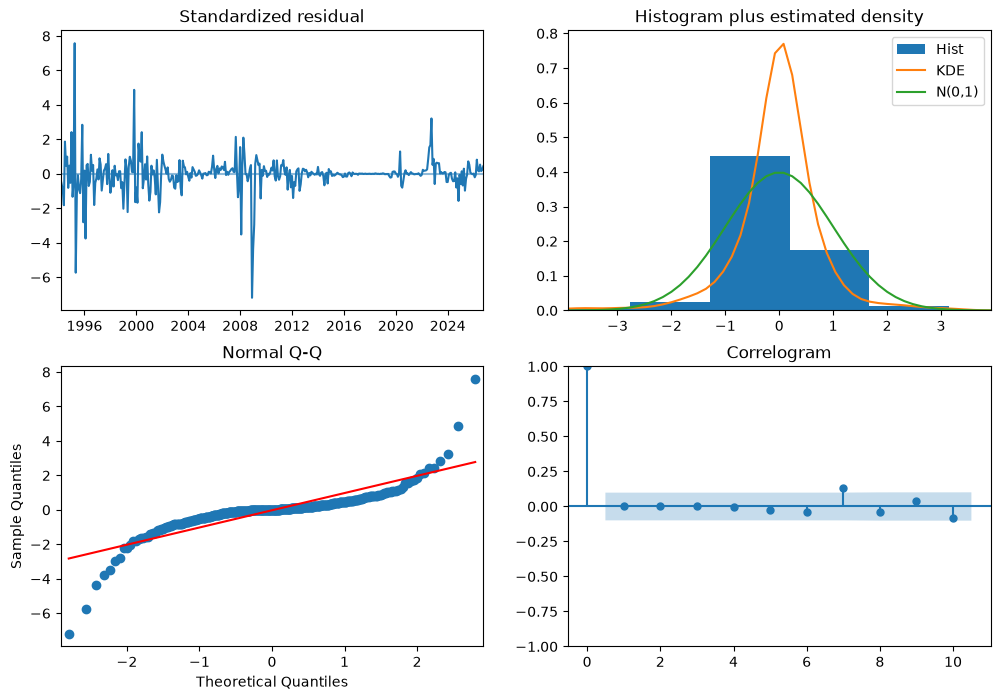

In [13]:
# AR domintant model. According to PACF graph, lags up to Lag 3 are significant. Set p = 3, d = 1 for ARIMA.
# Gradually decreasing significance of ACF values and sharply decreasing PACH values indicate that the model is AR dominant. Look for optimal 
# Confirming with auto_arima

import pmdarima as pm

auto_arima_model = pm.auto_arima(df['euribor'],d=1, start_p=1, max_p=3, start_q=0, max_q=2, seasonal=False, stepwise=True, information_criterion='aic', trace=True)
print(auto_arima_model.summary().tables[1])

auto_arima_model.plot_diagnostics(figsize=(12,8))

In [20]:
# No major issues arise from diagnostics, early data displays varying residuals. Histogram displays leptokurtosis and QQ-plot deviates slightly at tail ends
# both of these features are common for financial time series data. 
# 
# Proceeding to ARIMA forecast 12 months ahead with 95% confidence intervals.
forecast_horizon = 12
arima_forecast, arima_conf_int = auto_arima_model.predict(n_periods=forecast_horizon, return_conf_int=True)

# future date index for plotting
last_date = df.index[-1]
future_dates = pd.date_range(start=last_date, periods=forecast_horizon + 1, freq='MS')[1:]

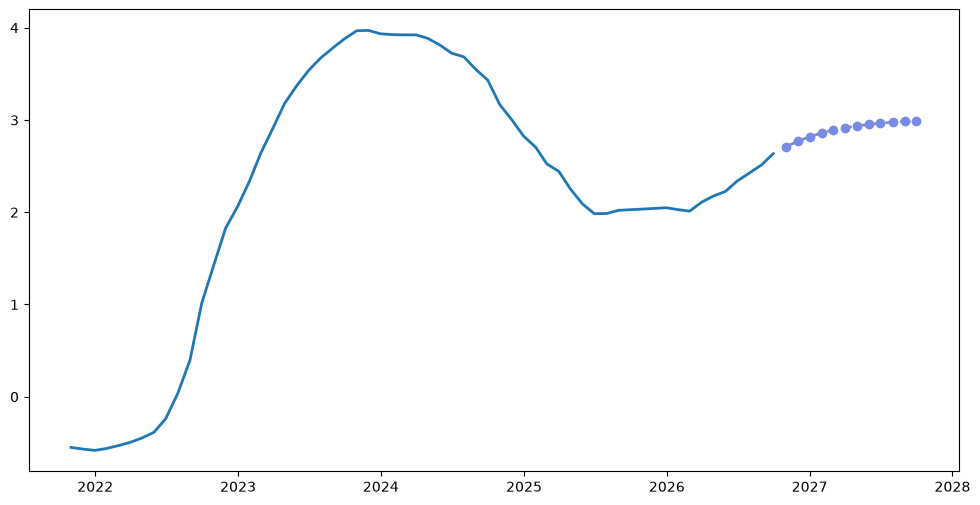

In [29]:
fig, ax = plt.subplots(figsize=(12, 6))

recent_df = df.tail(60)
ax.plot(recent_df.index, recent_df['euribor'], label='Historical Euribor Rate (12 months)', color='#1f77b4', lw=2)
ax.plot(future_dates, arima_forecast, label='ARIMA(3,1,0) Point Forecast', color="#778be3", linestyle='--', lw=2, marker='o',)

In [ ]:
# ARIMA forecast suggests that Euribor rate will continue to rise in the next 12 months. Rise will stabilize near 3.0% in the middle of 2027. 

# Implementing GARCH model to capture volatility clustering in Euribor rate changes.

from arch import arch_model

euribor_scaled = df['euribor_diff'].dropna() * 100

garch = arch_model(euribor_scaled, mean='Zero', p=1, q=1)
garch_fit = garch.fit(disp='off')
print(garch_fit.summary())

                       Zero Mean - GARCH Model Results                        
Dep. Variable:           euribor_diff   R-squared:                       0.000
Mean Model:                 Zero Mean   Adj. R-squared:                  0.003
Vol Model:                      GARCH   Log-Likelihood:               -1476.63
Distribution:                  Normal   AIC:                           2959.26
Method:            Maximum Likelihood   BIC:                           2971.17
                                        No. Observations:                  392
Date:                Thu, Oct 08 2026   Df Residuals:                      392
Time:                        15:23:11   Df Model:                            0
                            Volatility Model                            
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
omega          1.1665      1.485      0.786      0.432 [ -1.744,  4.07